# LeRobot Data Profiler (PySpark)

Profile any LeRobotDataset v3 folder to see whether it is sound enough to train on, and where it deviates from what its metadata claims. Built against PushT, then run on aloha_sim and an SO-101 dataset to compare sim and real.

## Setup

In [2]:
import os, glob
from pyspark.sql import SparkSession

os.environ["JAVA_HOME"] = "/opt/homebrew/opt/openjdk@17"

spark = (SparkSession
            .builder
                .master("local[*]")
                .appName("paida")
                .config("spark.driver.memory", "16g")
                .getOrCreate())

Spark's own glob did not match the local Hugging Face cache path in this environment (cause not diagnosed). <br>
Python's `glob` expands each pattern into an explicit file list, which is passed to Spark. `ROOT` is the only value that changes per dataset.

In [3]:
ROOT = os.path.expanduser("~/.cache/huggingface/lerobot/lerobot/pusht")

def files(sub):
    return glob.glob(f"{ROOT}/{sub}")

data_files = files("data/*/*.parquet")
episode_files = files("meta/episodes/*/*.parquet")
info_file = f"{ROOT}/meta/info.json"
video_files = files("videos/*/*/*.mp4")

print(video_files)

['/Users/snudurupati/.cache/huggingface/lerobot/lerobot/pusht/videos/observation.image/chunk-000/file-000.mp4']


## A. Dataset overview
**Goal:** know the shape of the dataset before measuring anything.<br>
**Details:** declared fps, total_episodes, total_frames, total_tasks. Declared shape and names of `action` and `observation.state`. The camera features.<br>
**Hint:** `features.action.shape` and `.names` come out of nested struct fields. If names is null, the dataset does not name its joints.<br>

In [4]:
#spark.conf.set("spark.sql.debug.maxToStringFields", 1000)

meta_df = (spark
            .read
            .option("multiline", "true")
            .json(info_file))
#meta_df.select("features").show(truncate=False)
meta_df.printSchema()

root
 |-- chunks_size: long (nullable = true)
 |-- codebase_version: string (nullable = true)
 |-- data_files_size_in_mb: long (nullable = true)
 |-- data_path: string (nullable = true)
 |-- features: struct (nullable = true)
 |    |-- action: struct (nullable = true)
 |    |    |-- dtype: string (nullable = true)
 |    |    |-- fps: double (nullable = true)
 |    |    |-- names: struct (nullable = true)
 |    |    |    |-- motors: array (nullable = true)
 |    |    |    |    |-- element: string (containsNull = true)
 |    |    |-- shape: array (nullable = true)
 |    |    |    |-- element: long (containsNull = true)
 |    |-- episode_index: struct (nullable = true)
 |    |    |-- dtype: string (nullable = true)
 |    |    |-- fps: double (nullable = true)
 |    |    |-- names: string (nullable = true)
 |    |    |-- shape: array (nullable = true)
 |    |    |    |-- element: long (containsNull = true)
 |    |-- frame_index: struct (nullable = true)
 |    |    |-- dtype: string (nullab

In [5]:
meta_df.selectExpr("total_episodes", "total_frames", "total_tasks", "fps", 
                    "features.`observation.state`.names AS state_names",
                    "features.`observation.state`.shape as state_shape",
                    "features.action.names as action_names",
                    "features.action.shape as action_shape"
                    ).show()

+--------------+------------+-----------+---+--------------------+-----------+--------------------+------------+
|total_episodes|total_frames|total_tasks|fps|         state_names|state_shape|        action_names|action_shape|
+--------------+------------+-----------+---+--------------------+-----------+--------------------+------------+
|           206|       25650|          1| 10|{[motor_0, motor_1]}|        [2]|{[motor_0, motor_1]}|         [2]|
+--------------+------------+-----------+---+--------------------+-----------+--------------------+------------+



## B. Episode counts and lengths
**Goal:** confirm the three sources agree on how much data there is, and see how episode length is distributed.<br>
**Details:** episode count from `info.json`, `meta/episodes` and `data`. Min, max, average length, plus percentiles. Which episodes are unusually short or long?<br>

In [6]:
episode_df = spark.read.parquet(*episode_files)
data_df = spark.read.parquet(*data_files)
episode_df.printSchema()
data_df.printSchema()

root
 |-- episode_index: long (nullable = true)
 |-- data/chunk_index: long (nullable = true)
 |-- data/file_index: long (nullable = true)
 |-- dataset_from_index: long (nullable = true)
 |-- dataset_to_index: long (nullable = true)
 |-- videos/observation.image/chunk_index: long (nullable = true)
 |-- videos/observation.image/file_index: long (nullable = true)
 |-- videos/observation.image/from_timestamp: double (nullable = true)
 |-- videos/observation.image/to_timestamp: double (nullable = true)
 |-- tasks: array (nullable = true)
 |    |-- element: string (containsNull = true)
 |-- length: long (nullable = true)
 |-- stats/observation.image/min: array (nullable = true)
 |    |-- element: array (containsNull = true)
 |    |    |-- element: array (containsNull = true)
 |    |    |    |-- element: double (containsNull = true)
 |-- stats/observation.image/max: array (nullable = true)
 |    |-- element: array (containsNull = true)
 |    |    |-- element: array (containsNull = true)
 |  

In [7]:
#episode stats from metadata
episode_df.selectExpr("count(episode_index) as total_episodes",
                        "sum(length) as total_frames",
                        "min(length) as min_ep_length",
                        "max(length) as max_ep_length",
                        "avg(length) as avg_ep_length"
                        ).show()

#episode stats from data
data_df.selectExpr("count(distinct episode_index) as total_episodes",
                    "count(frame_index) as total_frames",
                    ).show()


+--------------+------------+-------------+-------------+------------------+
|total_episodes|total_frames|min_ep_length|max_ep_length|     avg_ep_length|
+--------------+------------+-------------+-------------+------------------+
|           206|       25650|           49|          246|124.51456310679612|
+--------------+------------+-------------+-------------+------------------+

+--------------+------------+
|total_episodes|total_frames|
+--------------+------------+
|           206|       25650|
+--------------+------------+



### Per-episode cross-check: 
Matching totals don’t prove each episode matches.<br> 
One episode with extra frames and another with missing frames would cancel out. Compare each episode’s length to its frame count in data.

In [8]:
# Verify frames per episode between the metadata and data
import pyspark.sql.functions as F

(episode_df.groupBy("episode_index").agg(F.sum("length").alias("frame_count"))
.exceptAll(
data_df.groupBy("episode_index").agg(F.count("frame_index").alias("frame_count"))
)).count()

0

### Episode length distribution

Goal: find episodes with unusual lengths, meaning much shorter or longer than the rest, so they can be inspected. The plot sorts all episodes by length (frames), so the shortest sit on the left and the longest on the right. A flat middle means most episodes are similar; sharp bends at either end mark the unusual ones.

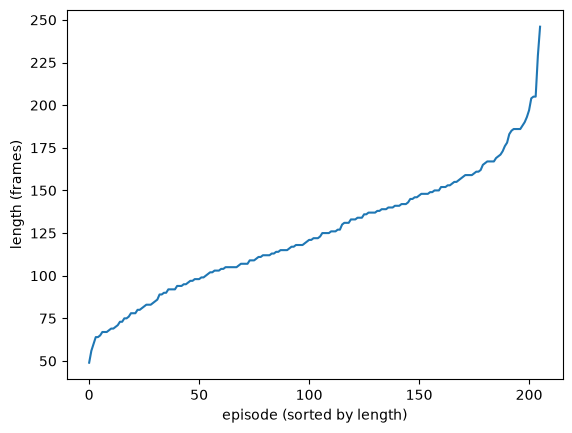

In [9]:
# one-time: uv add --dev matplotlib
import matplotlib.pyplot as plt

lengths = [r["length"] for r in episode_df.select("length").orderBy("length").collect()]

plt.plot(lengths)
plt.xlabel("episode (sorted by length)")
plt.ylabel("length (frames)")
plt.show()

25th percentile: 99 frames
50th percentile: 122 frames
75th percentile: 148 frames


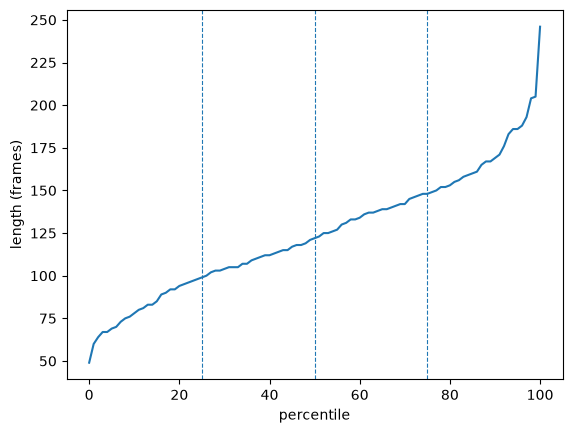

In [10]:
import pyspark.sql.functions as F
import matplotlib.pyplot as plt

pcts = [i / 100 for i in range(0, 101)]          # 0.00, 0.01, ... 1.00
#print(len(pcts))
vals = (episode_df
        .select(F.percentile_approx("length", pcts, 10000).alias("v"))
        .first()["v"])   
#print(vals)
plt.plot([p * 100 for p in pcts], vals)
for q in (25, 50, 75):
    plt.axvline(q, linestyle="--", linewidth=0.8)
    print(f"{q}th percentile: {vals[q]} frames")
plt.xlabel("percentile")
plt.ylabel("length (frames)")
plt.show()

### IQR (interquartile range) 
75th percentile minus 25th percentile = 148 - 99 = 49 frames.<br>

* What it measures: how spread out the middle half of your episodes is. A small IQR means episodes are all similar in length, and a large one means they vary a lot.
* Why use it instead of min and max: the shortest and longest episodes are the very ones you’re trying to judge. IQR ignores the extreme quarter at each end, so one odd episode can’t distort the yardstick.
* How it serves your goal: it gives you a ruler for “how far from normal is too far.” Instead of saying an episode looks long, you can say it’s more than some number of IQRs beyond the middle band.

In [11]:
q1 = vals[25]
q3 = vals[75]
iqr = q3 - q1
print(q1, q3, iqr)

99 148 49


### Outlier episodes (1.5 x IQR rule)

Goal: flag episodes whose length is unusually short or long, so they can be inspected before training.

- Percentiles: sorting the 206 episode lengths and reading values at each percent shows what is normal. The 25th, 50th and 75th percentiles split the episodes into four equal groups.
- IQR (interquartile range): 75th minus 25th percentile, the spread of the middle half of episodes. Extreme episodes cannot distort it.
- Fences: Q1 - 1.5 x IQR and Q3 + 1.5 x IQR. Episodes outside them are flagged. The 1.5 is a common convention, not a law.
- Flagged episodes are candidates to look at (for example in Rerun), not automatically bad data.

In [12]:
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print(lower, upper)

outliers = (episode_df
            .filter((F.col("length") < lower) | (F.col("length") > upper))
            .select("episode_index", "length")
            .orderBy("length"))
outliers.show()

25.5 221.5
+-------------+------+
|episode_index|length|
+-------------+------+
|          184|   229|
|          174|   246|
+-------------+------+



### Inspect an episode in Rerun

Open a single episode to watch what happened, for example one flagged by the length outlier check. Run from the repo root:

    uv run lerobot-dataset-viz --repo-id lerobot/pusht --episode-index 184

- Rerun does not autoplay, so press play.
- Watch the `action` and `observation.state` lines. They sit on top of each other until the pusher presses against the block.
- Compare a flagged episode (174, 184) with one near the median (for example 100).
- Change `--repo-id` and `--episode-index` for other datasets and episodes.

## Check C: are frames evenly spaced at the declared fps?

**Goal:** for every frame, `timestamp * fps` should equal `frame_index`. Any gap means a dropped frame or jitter.

In [60]:
fps, total_frames = meta_df.select("fps", "total_frames").first()
#print(fps, total_frames)
data_df2 = data_df.withColumn("calc_fr_idx",
                    F.round(F.col("timestamp")*F.lit(fps))
                    .cast("int"))
frame_count = data_df2.where("calc_fr_idx == frame_index").count()
assert frame_count == total_frames

## D. Video windows vs frame counts

**Goal:** confirm that the video clip each episode points to is as long as the episode’s data.

**Details:** per episode and per camera, compare to_timestamp - from_timestamp with frame count divided by fps. Report episodes that disagree.